# CCI620 – Inteligência Artificial
## Laboratório: Introdução ao Processamento de Imagens
**Prof. Dr. Danilo H. Perico**


**Instruções:** complete as células marcadas com `# TODO`. Sempre que houver uma **Pergunta**, responda em uma célula de texto logo abaixo.
Não use bibliotecas além de `numpy`, `cv2`, `matplotlib` e `skimage` (apenas para carregar imagens de exemplo).

## Preparação do ambiente

In [4]:
!pip install opencv-python scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 1.2 MB/s  0:00:11a 0:00:01m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 1.2 MB/s  0:00:011.2 MB/s eta 0:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-image]0m 3/4 [scikit-image]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


/home/schneider/.pyenv/versions/3.12.11/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/schneider/.pyenv/versions/3.12.11/lib/python3.12/site-packages/paramiko/pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  "cipher": algorithms.TripleDES,
/home/schneider/.pyenv/versions/3.12.11/lib/python3.12/site-packages/paramiko/transport.py:253: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  "class": algorithms.TripleDES,


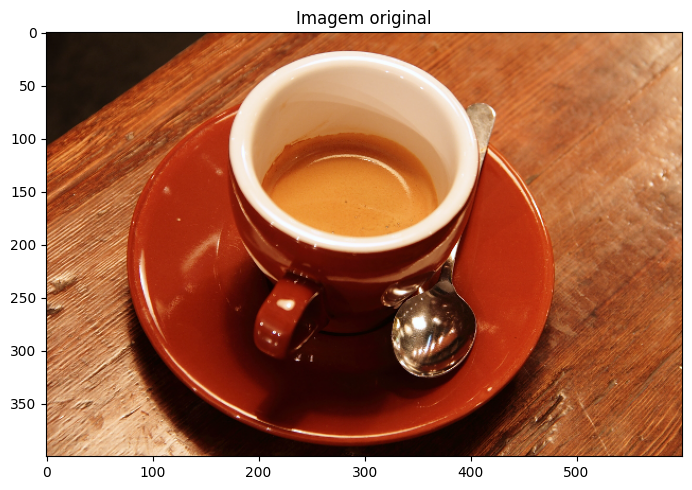

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

def mostrar(imagens, titulos=None, cmap=None, figsize=(15, 5)):
    """Exibe uma lista de imagens lado a lado.
    Imagens com 3 canais são consideradas BGR (padrão do OpenCV) e convertidas para RGB."""
    if not isinstance(imagens, (list, tuple)):
        imagens, titulos = [imagens], [titulos]
    titulos = titulos or [''] * len(imagens)
    fig, eixos = plt.subplots(1, len(imagens), figsize=figsize)
    eixos = np.atleast_1d(eixos)
    for ax, img, tit in zip(eixos, imagens, titulos):
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or 'gray', vmin=0, vmax=255 if img.dtype == np.uint8 else None)
        ax.set_title(tit)
    plt.tight_layout()
    plt.show()

# Imagem de exemplo (skimage entrega em RGB; convertemos para BGR,
# exatamente como teríamos após um cv2.imread)
imagem = cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR)

# Para usar sua própria imagem, descomente:
# imagem = cv2.imread('minha_imagem.jpg')

mostrar(imagem, 'Imagem original')

## Representação da imagem

Uma imagem colorida é representada por 3 matrizes (canais) de inteiros sem sinal de 8 bits.

**Exercício 1.1** – Imprima: a forma (`shape`), o tipo (`dtype`), a altura, a largura, o número de canais e o número total de pixels da imagem.

In [7]:
# TODO
altura, largura, canais = imagem.shape
print('shape:', imagem.shape)
print('dtype:', imagem.dtype)
print('Altura:', altura, '| Largura:', largura, '| Canais:', canais)
print('Total de pixels:', imagem.size)

shape: (400, 600, 3)
dtype: uint8
Altura: 400 | Largura: 600 | Canais: 3
Total de pixels: 720000


**Exercício 1.2** – Imprima o valor do pixel na linha 100, coluna 250. Em seguida, imprima separadamente os valores dos canais **R**, **G** e **B** desse pixel.

> Lembre-se: o OpenCV trabalha com **BGR**, e não RGB!

In [8]:
# TODO
pixel = imagem[100,250]
b, g, r = imagem[100,250][0], imagem[100,250][1], imagem[100,250][2]
print('Pixel (BGR):', pixel)
print(f'R={r}, G={g}, B={b}')

Pixel (BGR): [ 31 100 189]
R=189, G=100, B=31


**Exercício 1.3** – Exiba a imagem com `plt.imshow` **sem** converter de BGR para RGB, ao lado da imagem corretamente convertida. Depois, separe os três canais com `cv2.split` e exiba cada um em escala de cinza.

**Pergunta 1.3:** Por que as cores ficam "trocadas" na primeira exibição? Em qual canal a xícara aparece mais clara? Por quê?

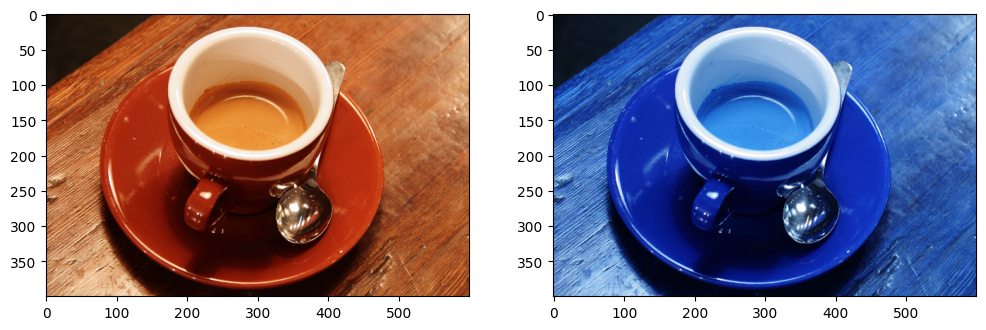

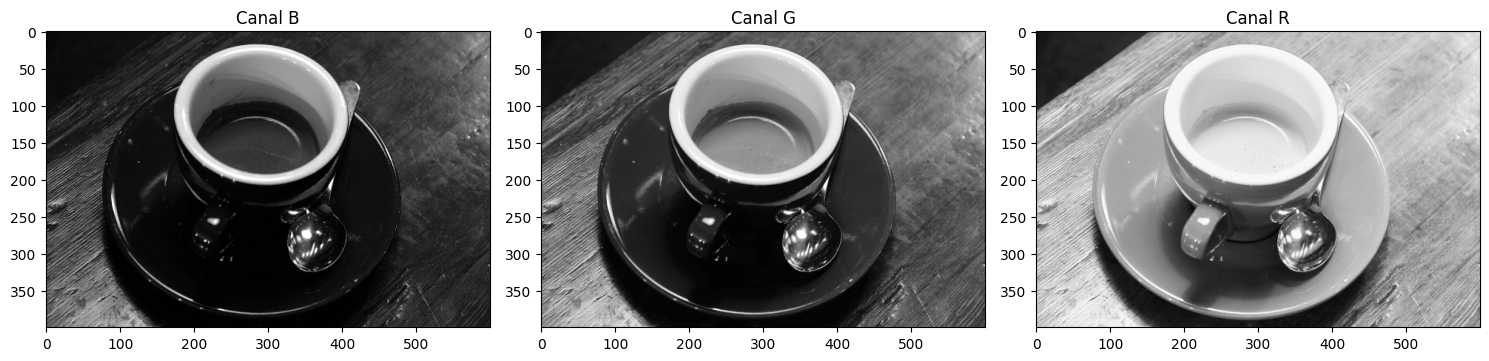

In [16]:
# TODO: exibição errada x correta
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

img_rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
ax[0].imshow(img_rgb)
ax[1].imshow(imagem)

plt.show()

b, g, r = cv2.split(imagem)
mostrar([b, g, r], ['Canal B', 'Canal G', 'Canal R'])

**Resposta 1.3**: As cores se invertem pois a ordem dos canais se invertem (BGR -> RGB); A xícara aparece mais clara no canal R, pois é a cor predominante da imagem

**Exercício 1.4** – Quantas cores **distintas** existem na imagem? Compare com o máximo teórico de 256³.

*Dica:* `np.unique(..., axis=0)` sobre a imagem redimensionada para `(-1, 3)`.

In [21]:
n_cores = np.unique(imagem.reshape(-1,3), axis=0)
print('Cores distintas:', n_cores.size)
print('Máximo teórico :', 256**3)

Cores distintas: 283434
Máximo teórico : 16777216


## Manipulação de pixels, desenhos, recorte e flip

**Exercício 2.1** – Em uma **cópia** da imagem (`imagem.copy()`):
- pinte de **vermelho** o quadrado de 100×100 pixels no canto superior esquerdo, apenas atribuindo valores à matriz;
- pinte de **verde** o quadrado de 100×100 no canto **inferior direito**, sem usar valores fixos de altura/largura (use índices negativos ou `shape`).

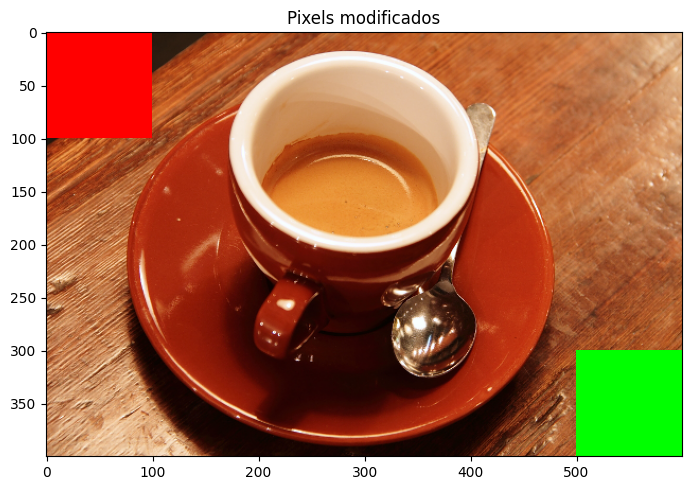

In [37]:
img2 = imagem.copy()
img2[0:100, 0:100] = [0,0,255]
img2[imagem.shape[0]-100:imagem.shape[0], imagem.shape[1]-100:imagem.shape[1]] = [0,255,0]

mostrar(img2, 'Pixels modificados')

**Exercício 2.2** – Em outra cópia, desenhe:
- uma **linha** azul do canto superior esquerdo ao canto inferior direito (espessura 5);
- um **retângulo** amarelo (só a borda, espessura 3) ao redor da xícara;
- um **círculo** preenchido branco de raio 20 no centro da imagem;
- o texto `"CCI620"` com `cv2.putText`.

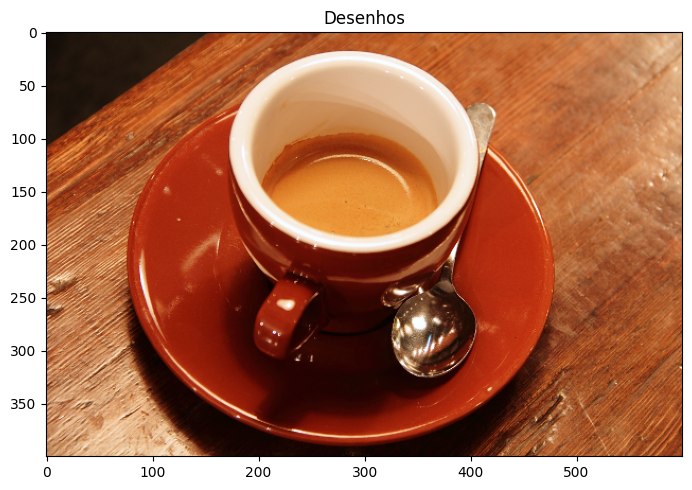

In [ ]:
img3 = imagem.copy()
# TODO: cv2.line, cv2.rectangle, cv2.circle, cv2.putText

mostrar(img3, 'Desenhos')

**Exercício 2.3** – Recorte a região da xícara usando *slicing* (`imagem[y1:y2, x1:x2]`) e exiba-a.
Depois, **cole** esse recorte no canto superior esquerdo de uma cópia da imagem original.

In [ ]:
# TODO
recorte = None
img4 = imagem.copy()
# img4[...] = recorte

# mostrar([recorte, img4], ['Recorte', 'Recorte colado'])

**Exercício 2.4** – Usando apenas *slicing*, gere três imagens: invertida **de cima para baixo**, invertida **da esquerda para a direita** e **ambas**. Confirme o resultado com `cv2.flip` (códigos `0`, `1` e `-1`), usando `np.array_equal`.

**Pergunta 2.4:** `imagem[::-1, :]` inverte qual eixo — linhas ou colunas? O resultado é uma reflexão em torno de um eixo horizontal ou vertical?

In [ ]:
# TODO
cima_baixo = None
esq_dir = None
ambos = None

# print(np.array_equal(cima_baixo, cv2.flip(imagem, 0)))
# ...
# mostrar([cima_baixo, esq_dir, ambos], ['Cima ↔ baixo', 'Esquerda ↔ direita', 'Ambos'])

## Escala de cinza

A conversão é feita por média ponderada: **Cinza = 0.299R + 0.587G + 0.114B**

**Exercício 3.1** – Implemente a função `para_cinza(img_bgr)` usando **apenas NumPy** (sem `cvtColor`) e compare com `cv2.cvtColor(..., cv2.COLOR_BGR2GRAY)`. Calcule a maior diferença absoluta entre as duas.

*Cuidado:* faça as contas em `float` e converta para `uint8` ao final.

In [ ]:
def para_cinza(img_bgr):
    # TODO
    pass

cinza_manual = para_cinza(imagem)
cinza_cv = cv2.cvtColor(imagem, cv2.COLOR_BGR2GRAY)

# print('Maior diferença:', ...)
# mostrar([cinza_manual, cinza_cv], ['Manual', 'OpenCV'])

**Exercício 3.2** – Calcule também a média simples `(R + G + B) / 3` e exiba ao lado da versão ponderada.

**Pergunta 3.2:** Por que o verde recebe o maior peso na fórmula ponderada? Onde você percebe diferença visual entre as duas versões?

In [ ]:
# TODO
cinza_media = None
# mostrar([cinza_media, cinza_manual], ['Média simples', 'Ponderada'])

## Convolução

**Exercício 4.1** – Implemente `convolucao(img, kernel)` com laços `for`, para imagens em escala de cinza e kernels quadrados de tamanho ímpar.
- A saída deve ter o mesmo tamanho da entrada: use *padding* replicando a borda (`np.pad(..., mode='edge')`).
- Faça as contas em `float` e, ao final, limite os valores a [0, 255] com `np.clip`.

> Observação: assim como na aula (e no `cv2.filter2D`), aplicaremos o kernel diretamente sobre a vizinhança, sem rotacioná-lo. Para kernels simétricos, não há diferença.

In [ ]:
def convolucao(img, kernel):
    k = kernel.shape[0] // 2
    # TODO: padding
    # TODO: laços sobre linhas e colunas, somatório (vizinhança * kernel)
    pass

**Exercício 4.2** – Verifique sua função com o exemplo da aula. Calcule **à mão** o valor do pixel central da vizinhança abaixo com o kernel de *sharpen* (como na aula: 5·60 + (−1·113) + (−1·73) + 0·121 + ...) e confira com a sua função.

Depois, compare sua implementação com `cv2.filter2D` (use `borderType=cv2.BORDER_REPLICATE`) em uma versão reduzida da imagem em cinza.

In [ ]:
kernel_sharpen = np.array([[ 0, -1,  0],
                           [-1,  5, -1],
                           [ 0, -1,  0]], dtype=np.float64)

# Vizinhança 3x3 para teste (centro = 60)
teste = np.array([[121, 113,  90],
                  [ 73,  60,  30],
                  [ 50,  20, 200]], dtype=np.uint8)

# TODO: aplique sua função e imprima o pixel central
# TODO: compare com cv2.filter2D em uma imagem pequena
pequena = cv2.resize(cinza_cv, None, fx=0.25, fy=0.25)

**Exercício 4.3** – Aplique, com `cv2.filter2D`, os kernels abaixo à imagem em cinza e exiba os resultados. Descreva em uma frase o efeito de cada um.
- Identidade: `[[0,0,0],[0,1,0],[0,0,0]]`
- Média 3×3
- Sharpen (do exercício anterior)
- `[[-1,-1,-1],[-1,8,-1],[-1,-1,-1]]`

**Pergunta 4.3:** Quanto vale a soma dos elementos de cada kernel? Qual a relação entre essa soma e o brilho médio da imagem de saída?

In [ ]:
# TODO

## Suavização: média, mediana e Gaussiano

Vamos corromper a imagem em cinza com dois tipos de ruído e verificar qual filtro funciona melhor em cada caso.
A qualidade será medida pelo **PSNR** (*Peak Signal-to-Noise Ratio*, em dB) em relação à imagem original: quanto maior, melhor.

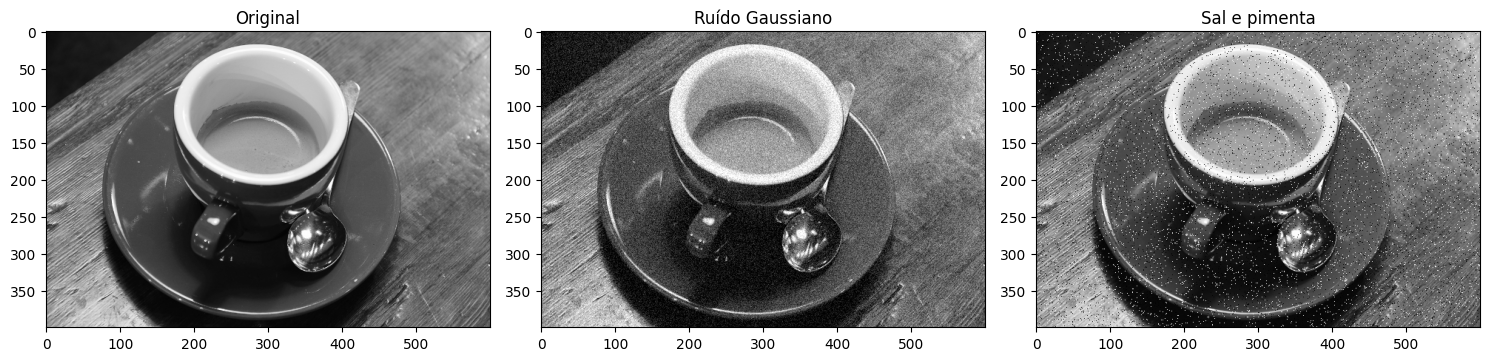

PSNR ruído Gaussiano: 22.36 dB
PSNR sal e pimenta  : 18.10 dB


In [ ]:
rng = np.random.default_rng(42)

# Ruído Gaussiano (média 0, desvio 20)
ruido = rng.normal(0, 20, cinza_cv.shape)
img_gauss = np.clip(cinza_cv + ruido, 0, 255).astype(np.uint8)

# Ruído sal e pimenta (5% dos pixels)
img_sp = cinza_cv.copy()
sorteio = rng.random(cinza_cv.shape)
img_sp[sorteio < 0.025] = 0
img_sp[sorteio > 0.975] = 255

mostrar([cinza_cv, img_gauss, img_sp], ['Original', 'Ruído Gaussiano', 'Sal e pimenta'])
print(f'PSNR ruído Gaussiano: {cv2.PSNR(cinza_cv, img_gauss):.2f} dB')
print(f'PSNR sal e pimenta  : {cv2.PSNR(cinza_cv, img_sp):.2f} dB')

**Exercício 5.1** – Implemente o **filtro da mediana** manualmente (`mediana_manual(img, k)`), com laços e `np.median`. Teste com a matriz da aula: na vizinhança 3×3 em torno de (1,1) o resultado deve ser **5**.

In [ ]:
def mediana_manual(img, k=3):
    # TODO
    pass

m = np.array([[9, 4, 5, 7],
              [10, 3, 2, 8],
              [9, 1, 6, 0],
              [3, 2, 7, 4]], dtype=np.uint8)
# print(mediana_manual(m, 3)[1, 1])

**Exercício 5.2** – Para **cada** imagem ruidosa, aplique `cv2.blur`, `cv2.medianBlur` e `cv2.GaussianBlur`, todos com kernel 5×5. Monte uma tabela com o PSNR de cada combinação e exiba as imagens.

**Pergunta 5.2:** Qual filtro foi melhor para o ruído sal e pimenta? E para o Gaussiano? Explique pelo funcionamento de cada filtro (média × valor ordenado).

In [ ]:
# TODO

**Exercício 5.3** – Aplique `cv2.GaussianBlur` à imagem original com kernels 3, 9, 21 e 41 (σ automático). O que acontece com os detalhes?
Depois, fixe o kernel em 21×21 e varie σ entre 1, 3 e 10. Qual parâmetro controla de fato a intensidade da suavização?

In [ ]:
# TODO

## Limiarização (threshold)

**Exercício 6.1** – Implemente a limiarização binária com NumPy (`dst = 255 se src > T, senão 0`) e verifique, com `np.array_equal`, que o resultado é idêntico a `cv2.threshold(cinza, T, 255, cv2.THRESH_BINARY)` para T = 150.

In [ ]:
def limiar_binario(img, T):
    # TODO
    pass

# TODO: comparar com cv2.threshold

**Exercício 6.2** – Plote o **histograma** da imagem em cinza (`plt.hist(cinza.ravel(), 256)`) e exiba as imagens binárias com T = 50, 100, 150 e 200.
Em seguida, use o método de **Otsu** (`cv2.THRESH_BINARY + cv2.THRESH_OTSU`), que escolhe o limiar automaticamente, e imprima o valor escolhido. Marque esse valor no histograma com `plt.axvline`.

**Pergunta 6.2:** O limiar de Otsu fica em qual região do histograma? Por que ele precisa de uma imagem em escala de cinza?

In [ ]:
# TODO

## Morfologia matemática

A célula abaixo cria uma imagem binária com alguns objetos, pontos de ruído branco e "furos" pretos dentro dos objetos.

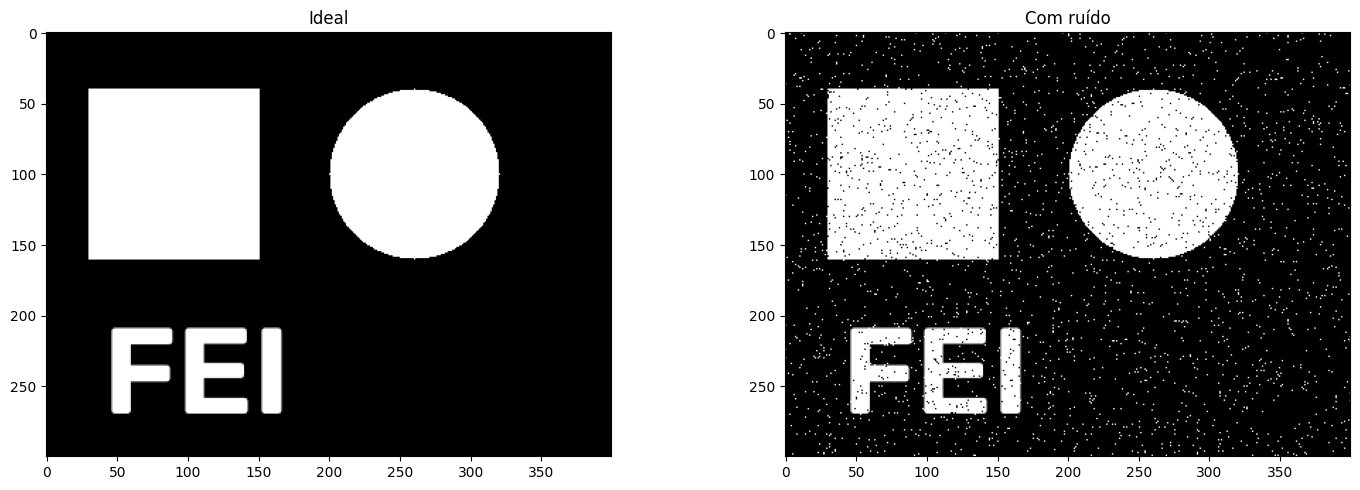

In [ ]:
binaria = np.zeros((300, 400), np.uint8)
cv2.rectangle(binaria, (30, 40), (150, 160), 255, -1)
cv2.circle(binaria, (260, 100), 60, 255, -1)
cv2.putText(binaria, 'FEI', (40, 270), cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 12)

rng = np.random.default_rng(0)
ruido = rng.random(binaria.shape)
binaria_ruidosa = binaria.copy()
binaria_ruidosa[ruido < 0.02] = 255                         # ruído branco no fundo
binaria_ruidosa[(ruido > 0.97) & (binaria == 255)] = 0      # furos nos objetos

mostrar([binaria, binaria_ruidosa], ['Ideal', 'Com ruído'])

**Exercício 7.1** – Com um elemento estruturante `np.ones((5,5), np.uint8)`, aplique `cv2.erode` e `cv2.dilate` (1 iteração) à imagem ruidosa e exiba. Conte quantos pixels brancos há em cada resultado (`np.count_nonzero`).

**Pergunta 7.1:** O que a erosão fez com o ruído branco? E com os furos pretos? E a dilatação?

In [ ]:
kernel = np.ones((5, 5), np.uint8)
# TODO

**Exercício 7.2** – Combine as operações elementares:
- **Abertura** = erosão seguida de dilatação
- **Fechamento** = dilatação seguida de erosão

Implemente as duas **usando apenas `cv2.erode` e `cv2.dilate`**, confira com `cv2.morphologyEx` (`cv2.MORPH_OPEN` / `cv2.MORPH_CLOSE`) e, por fim, encontre uma sequência que **remova o ruído e feche os furos**. Avalie quantos pixels diferem da imagem ideal.

In [ ]:
# TODO

## Detectores de borda

**Exercício 8.1 – Sobel.** Aplique `cv2.Sobel` à imagem em cinza para obter as derivadas em x (`dx=1, dy=0`) e em y (`dx=0, dy=1`), com `ddepth=cv2.CV_64F` e `ksize=3`.
Calcule a **magnitude do gradiente** `sqrt(Gx² + Gy²)` e converta os três resultados para exibição com `cv2.convertScaleAbs`.

**Pergunta 8.1:** Por que usamos `CV_64F` e não `uint8` como profundidade de saída? (Pense no sinal da derivada.)

In [ ]:
# TODO

**Exercício 8.2 – Sobel "na mão".** Aplique, com a sua função `convolucao` (ou `cv2.filter2D` com `ddepth=cv2.CV_64F`), o kernel de Sobel X abaixo sobre a imagem reduzida `pequena` e compare com `cv2.Sobel`.

```
[-1  0  1]
[-2  0  2]
[-1  0  1]
```
*Atenção:* sua função `convolucao` corta valores negativos. Pense em como contornar isso.

In [ ]:
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float64)
# TODO

**Exercício 8.3 – Laplaciano.** Aplique `cv2.Laplacian` (`CV_64F`) à imagem original em cinza e à imagem com **ruído Gaussiano** (`img_gauss`). Depois, aplique de novo à imagem ruidosa previamente suavizada com `GaussianBlur` 5×5.

**Pergunta 8.3:** Por que o Laplaciano é tão sensível ao ruído? O que a suavização prévia muda?

In [ ]:
# TODO

**Exercício 8.4 – Canny.** Aplique `cv2.Canny` à imagem em cinza com os pares de limiares (50, 100), (100, 200) e (200, 400). Para cada um, imprima a porcentagem de pixels de borda.
Em seguida, teste `(100, 200)` sobre `img_gauss` com e sem `GaussianBlur` prévio.

**Pergunta 8.4:** Explique, usando as quatro etapas do Canny vistas em aula (suavização, gradiente, supressão de não-máximos e histerese), o efeito de aumentar os limiares.

In [ ]:
# TODO

## Segmentação por cor no espaço HSV

A célula abaixo gera uma cena sintética com objetos de várias cores e um pouco de ruído.

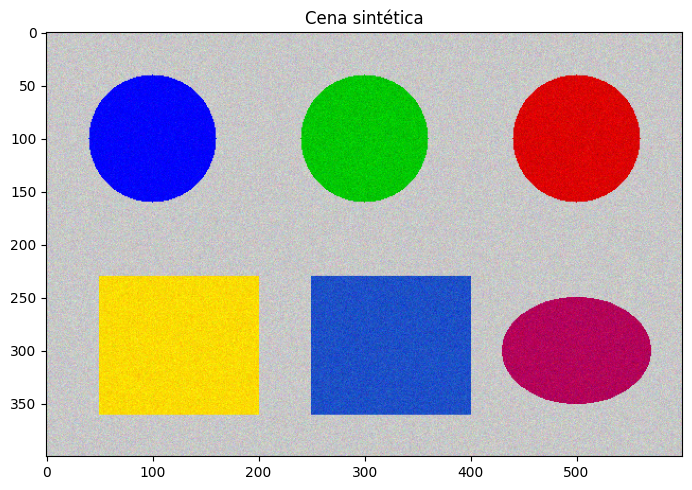

In [ ]:
cena = np.full((400, 600, 3), 200, np.uint8)              # fundo cinza claro
cv2.circle(cena, (100, 100), 60, (255, 0, 0), -1)         # azul (BGR)
cv2.circle(cena, (300, 100), 60, (0, 200, 0), -1)         # verde
cv2.circle(cena, (500, 100), 60, (0, 0, 220), -1)         # vermelho
cv2.rectangle(cena, (50, 230), (200, 360), (0, 220, 255), -1)   # amarelo
cv2.rectangle(cena, (250, 230), (400, 360), (200, 80, 30), -1)  # azul mais escuro
cv2.ellipse(cena, (500, 300), (70, 50), 0, 0, 360, (90, 0, 180), -1)  # vermelho arroxeado

rng = np.random.default_rng(1)
cena = np.clip(cena + rng.normal(0, 12, cena.shape), 0, 255).astype(np.uint8)
mostrar(cena, 'Cena sintética')

**Exercício 9.1** – Converta a cena para HSV e exiba os canais H, S e V separadamente. Imprima o valor HSV no centro de cada objeto.

**Pergunta 9.1:** Por que o canal **H** (matiz) é mais adequado para segmentar cor do que trabalhar diretamente no RGB/BGR?

In [ ]:
# TODO
hsv = None

**Exercício 9.2** – Segmente os objetos **azuis** com `cv2.inRange` usando a faixa da aula (`[100,100,50]` a `[130,255,255]`) e aplique a máscara com `cv2.bitwise_and`.
Os **dois** objetos azuis foram detectados?

In [ ]:
# TODO

**Exercício 9.3** – Segmente os objetos **vermelhos**. Lembre-se de que o vermelho fica nas **duas pontas** de H (perto de 0 e de 179): crie duas máscaras e combine-as com `cv2.bitwise_or`.
Em seguida, limpe a máscara com abertura morfológica e calcule, para cada máscara final, a **área** (número de pixels) ocupada pela cor.

In [ ]:
# TODO

**Exercício 9.4** – Escreva a função `segmentar(img_bgr, h_min, h_max, s_min=100, v_min=50)` que retorna a máscara limpa (com abertura) para qualquer faixa de matiz — tratando automaticamente o caso em que `h_min > h_max` (faixa que "dá a volta", como o vermelho).
Use-a para segmentar **verde** e **amarelo** e exiba as máscaras.

In [ ]:
def segmentar(img_bgr, h_min, h_max, s_min=100, v_min=50):
    # TODO
    pass

## Desafio integrador: onde está a bola?

Em competições de robótica (como as da RoboCup), uma das primeiras tarefas da visão do robô é localizar a bola no campo.
A célula abaixo gera um campo verde com linhas brancas, ruído e uma **bola laranja** em posição aleatória.

Escreva a função `localizar_bola(img_bgr)` que retorna `(x, y, raio)` do centro da bola, usando **apenas técnicas desta aula**:
1. Suavização para reduzir o ruído;
2. Conversão para HSV e segmentação da cor laranja;
3. Morfologia para limpar a máscara;
4. Centro = média das coordenadas dos pixels da máscara (`np.nonzero`); raio estimado a partir da área (`área = πr²`).

Desenhe um círculo e uma cruz sobre a bola detectada e imprima o **erro (em pixels)** entre a posição estimada e a verdadeira. Teste em pelo menos 5 cenas diferentes (sementes diferentes).

**Pergunta 10:** Em que situações reais (iluminação, outros objetos, oclusão) sua solução falharia? Por que tarefas de alto nível costumam usar aprendizado de máquina?

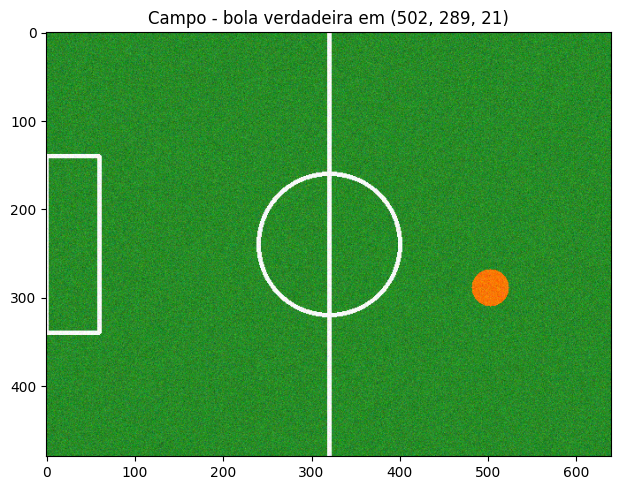

In [ ]:
def gerar_campo(seed):
    rng = np.random.default_rng(seed)
    campo = np.zeros((480, 640, 3), np.uint8)
    campo[:] = (40, 140, 40)                                   # verde (BGR)
    cv2.line(campo, (320, 0), (320, 479), (255, 255, 255), 4)
    cv2.circle(campo, (320, 240), 80, (255, 255, 255), 4)
    cv2.rectangle(campo, (0, 140), (60, 340), (255, 255, 255), 4)
    x, y, r = int(rng.integers(60, 580)), int(rng.integers(60, 420)), int(rng.integers(12, 30))
    cv2.circle(campo, (x, y), r, (0, 120, 255), -1)            # bola laranja
    campo = np.clip(campo + rng.normal(0, 15, campo.shape), 0, 255).astype(np.uint8)
    return campo, (x, y, r)

campo, verdade = gerar_campo(0)
mostrar(campo, f'Campo - bola verdadeira em {verdade}')

In [ ]:
def localizar_bola(img_bgr):
    # TODO
    pass

# TODO: teste com várias sementes, desenhe e calcule o erro

---
### Entrega
Envie o notebook executado, com todas as células de código completas e as respostas às perguntas.

Repita o desafio integrador com uma foto real (tirada por você) de um objeto de cor bem definida. Quais ajustes de faixa HSV foram necessários?